# Aim :To Perform and Analyse K-Nearest Neighbors (KNN)

In [ ]:
# Name: Sanika Vijay Kale
# Roll No.: 23
# Branch: B.E. CSE (Data Science)
# Year: Final Year
# Semester: VII
# Academic Year: 2026-27 


In [8]:
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

print("KNN practical started successfully!")

KNN practical started successfully!


In [9]:
iris = load_iris()

X = iris.data[:, :2]   # Sepal length and sepal width
y = iris.target

print("Features:", iris.feature_names[:2])
print("Flower types:", iris.target_names)
print("Total samples:", len(X))

Features: ['sepal length (cm)', 'sepal width (cm)']
Flower types: ['setosa' 'versicolor' 'virginica']
Total samples: 150


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


In [12]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [13]:
k_values = [1, 3, 5, 7, 9, 11, 13, 15]
accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)

    predictions = knn.predict(X_test_scaled)
    acc = accuracy_score(y_test, predictions)

    accuracies.append(acc * 100)

    print(f"K = {k:2d}  |  Accuracy = {acc * 100:.2f}%")

K =  1  |  Accuracy = 70.00%
K =  3  |  Accuracy = 66.67%
K =  5  |  Accuracy = 63.33%
K =  7  |  Accuracy = 73.33%
K =  9  |  Accuracy = 66.67%
K = 11  |  Accuracy = 76.67%
K = 13  |  Accuracy = 70.00%
K = 15  |  Accuracy = 70.00%


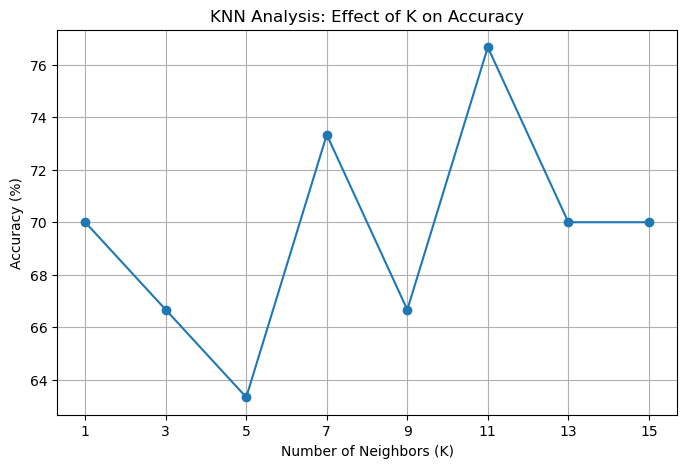

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, accuracies, marker="o")

plt.title("KNN Analysis: Effect of K on Accuracy")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy (%)")
plt.xticks(k_values)
plt.grid(True)

plt.show()

In [15]:
best_index = accuracies.index(max(accuracies))
best_k = k_values[best_index]
best_accuracy = accuracies[best_index]

print("Best K among tested values:", best_k)
print("Highest test accuracy:", round(best_accuracy, 2), "%")

Best K among tested values: 11
Highest test accuracy: 76.67 %


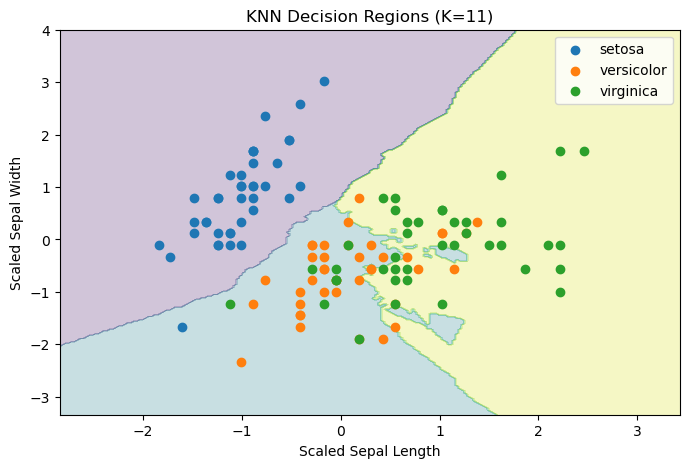

In [16]:
import numpy as np

best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X_train_scaled, y_train)

x_min = X_train_scaled[:, 0].min() - 1
x_max = X_train_scaled[:, 0].max() + 1
y_min = X_train_scaled[:, 1].min() - 1
y_max = X_train_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.03),
    np.arange(y_min, y_max, 0.03)
)

grid = np.c_[xx.ravel(), yy.ravel()]
Z = best_knn.predict(grid).reshape(xx.shape)

plt.figure(figsize=(8, 5))
plt.contourf(xx, yy, Z, alpha=0.25)

for i, name in enumerate(iris.target_names):
    mask = y_train == i
    plt.scatter(
        X_train_scaled[mask, 0],
        X_train_scaled[mask, 1],
        label=name
    )

plt.title(f"KNN Decision Regions (K={best_k})")
plt.xlabel("Scaled Sepal Length")
plt.ylabel("Scaled Sepal Width")
plt.legend()
plt.show()

In [17]:
new_flower = [[5.1, 3.5]]

new_flower_scaled = scaler.transform(new_flower)
prediction = best_knn.predict(new_flower_scaled)

print("Predicted flower:", iris.target_names[prediction[0]])

Predicted flower: setosa
